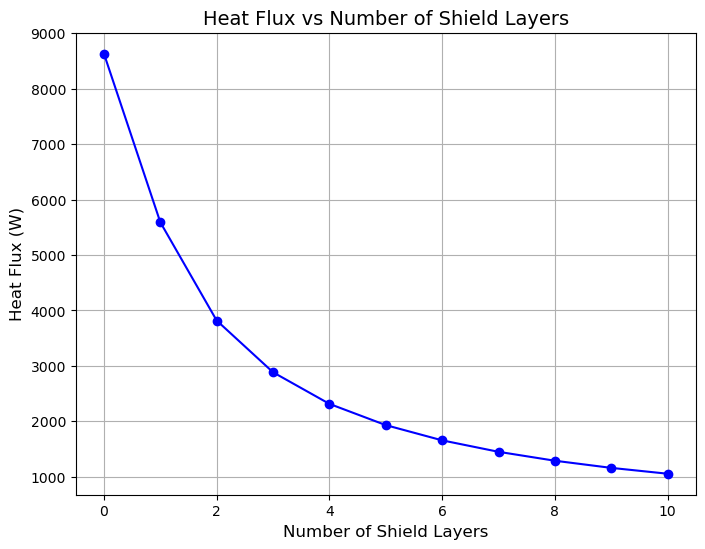

In [51]:
import scipy.constants as sp
import numpy as np
import CoolProp.CoolProp as CP
import matplotlib.pyplot as plt

def Rrad_2surfaces(T_1, T_2, A_1, A_2, emis_1, emis_2, VF_12):
    """
    Radiation thermal resistance between two grey bodies [K/W].
    """
    R_rad = ((1 - emis_1) / (A_1 * emis_1) + 1 / (A_1 * VF_12) + (1 - emis_2) / 
             (A_2 * emis_2)) / ((T_1 ** 2 + T_2 ** 2) * (T_1 + T_2) * sp.sigma)
    return R_rad

def Rrad(T_sur, T_s, A_s, VF, emis):
    #def exact radiation thermal resistance [K/W]
    return 1 / (A_s * emis * (T_s ** 2 + T_sur ** 2) * (T_sur + T_s) * sp.constants.sigma)

def w_tcx(temp: float) -> float:
    """
    Calculate the thermal conductivity of tungsten as a function of temperature.
    
    Parameters:
    temp (float): Temperature (K).
    
    Returns:
    float: Thermal conductivity of tungsten (W/mK).
    """
    # Example function for tungsten thermal conductivity; adjust this based on actual data.
    if temp < 300:
        return 173
    elif temp < 1000:
        return 173 - 0.03 * (temp - 300)
    else:
        return 152 - 0.01 * (temp - 1000)

def solve_surface_temperatures(
    num_surfaces,
    first_surface_area,
    first_surface_emissivity,
    first_surface_view_factor,
    subsequent_surface_area,
    subsequent_surface_emissivity,
    subsequent_surface_view_factor,
    cold_plate_emissivity,
    first_surface_temp,
    bottom_surface_temp,
    spacing,
    d_spacer,
    convergence_criteria=1e-6,
    max_iterations=1000,
):
    """
    Solve for the temperatures of multiple surfaces using radiative thermal resistance.

    Parameters:
        num_surfaces (int): Number of intermediate surfaces.
        first_surface_area (float): Surface area of the first surface (m^2).
        first_surface_emissivity (float): Emissivity of the first surface (dimensionless).
        first_surface_view_factor (float): View factor of the first surface to the next.
        subsequent_surface_area (float): Surface area of all subsequent surfaces (m^2).
        subsequent_surface_emissivity (float): Emissivity of all subsequent surfaces (dimensionless).
        subsequent_surface_view_factor (float): View factor for all subsequent surfaces.
        first_surface_temp (float): Temperature of the first surface (in K).
        bottom_surface_temp (float): Temperature of the last surface (in K).
        convergence_criteria (float): Threshold for convergence (default: 1e-6).
        max_iterations (int): Maximum number of iterations (default: 1000).

    Returns:
        tuple: Final temperatures of surfaces (array) and heat transfer (float).
    """
    # Initialize arrays for areas, emissivities, and view factors
    areas = np.full(num_surfaces + 2, subsequent_surface_area)
    emissivities = np.full(num_surfaces + 2, subsequent_surface_emissivity)
    view_factors = np.full(num_surfaces + 2, subsequent_surface_view_factor)

    # Set the first surface's unique values
    areas[0] = first_surface_area
    emissivities[0] = first_surface_emissivity
    emissivities[-1] = cold_plate_emissivity
    view_factors[0] = first_surface_view_factor
    # Initialize temperatures for all surfaces
    temperatures = np.linspace(first_surface_temp, bottom_surface_temp, num_surfaces + 2)
    temperatures[0] = first_surface_temp  # Fix the first surface temperature
    temperatures[-1] = bottom_surface_temp  # Fix the bottom surface temperature

    # Iterative solver
    iteration = 0
    converged = False

    while not converged and iteration < max_iterations:
        iteration += 1
        previous_temperatures = temperatures.copy()
        #print(previous_temperatures)
        # Calculate radiative thermal resistances between surfaces
        radiative_resistances = []
        for i in range(num_surfaces + 1):
            T1 = previous_temperatures[i]
            T2 = previous_temperatures[i + 1]
            A1 = areas[i]
            A2 = areas[i + 1]
            emis_1 = emissivities[i]
            emis_2 = emissivities[i + 1]
            VF_12 = view_factors[i]
            tc_Ar = CP.PropsSI('L', 'T', T1, 'P', 1e5, 'Argon')
            tc_spacer = w_tcx(T1)
            A_spacer = np.pi * d_spacer ** 2
            if i > 0: #for inra-shield layers
                R_Ar = spacing / (tc_Ar * A2)
                R_spacer = spacing / (tc_spacer * A_spacer)
                R_rad = Rrad_2surfaces(T1, T2, A1, A2, emis_1, emis_2, VF_12)
                R_tot = 1 / (1 / R_rad + 1 / R_Ar + 1 / R_spacer)
            else:
                R_Ar = 0
                R_spacer = 0
                R_rad = Rrad_2surfaces(T1, T2, A1, A2, emis_1, emis_2, VF_12)
                R_tot = R_rad
            
            #print(R_tot, R_rad, R_Ar, R_spacer)
            #print(A1, A2, VF_12, R_rad, R_tot)
            radiative_resistances.append(R_tot)

        # Calculate total thermal resista
        total_resistance = sum(radiative_resistances)
        #print(radiative_resistances)
        # Calculate heat transfer
        heat_transfer = (first_surface_temp - bottom_surface_temp) / total_resistance

        # Update surface temperatures
        for i in range(1, num_surfaces + 1):
            temperatures[i] = temperatures[i - 1] - heat_transfer * radiative_resistances[i - 1]

        # Check for convergence
        max_change = np.max(np.abs(temperatures - previous_temperatures))
        if max_change < convergence_criteria:
            converged = True

    # Check if the solver failed to converge
    if not converged:
        raise ValueError(f"Solver did not converge after {max_iterations} iterations.")

    return temperatures, heat_transfer



# Define parameters
#num_surfaces = 10  # Number of intermediate surfaces
W = 0.13 #shield width, m
d= 0.001 #shield spacing, m
d_spacer = 0.0008
emis_emit = 0.3
emis_shield = 0.3
emis_plate = 0.3
area_shield = W ** 2
area_emit = area_shield
#VF_emit = area_shield / area_emit
VF_emit = 1
VF_shield = (((W / d) ** 2 + 1) ** 0.5 - 1) * d / W
first_surface_temp = 2673  # First surface temperature (in K)
bottom_surface_temp = 313.0  # Bottom surface temperature (in K)
# Range of shield layers (num_surfaces)
num_surfaces_range = range(0, 11)
# Store heat flux results
heat_flux_values = []
# Solve for surface temperatures
for num_surfaces in num_surfaces_range:
    final_temperatures, heat_flux = solve_surface_temperatures(
            num_surfaces,
            area_emit,
            emis_emit,
            VF_emit,
            area_shield,
            emis_shield,
            VF_shield,
            emis_plate,
            first_surface_temp,
            bottom_surface_temp,
            d,
            d_spacer,
        )
    heat_flux_values.append(heat_flux)

# Print results
#print("Final Surface Temperatures (K):")
#for i, temp in enumerate(final_temperatures):
#    print(f"Surface {i + 1}: {temp:.6f} K")

#print(f"\nHeat Flux: {heat_flux:.6f} W/m^2")
 # Plot heat flux vs number of shield layers
plt.figure(figsize=(8, 6))
plt.plot(num_surfaces_range, heat_flux_values, marker="o", linestyle="-", color="b")
plt.title("Heat Flux vs Number of Shield Layers", fontsize=14)
plt.xlabel("Number of Shield Layers", fontsize=12)
plt.ylabel("Heat Flux (W)", fontsize=12)
plt.grid(True)
plt.show()

In [19]:
sp.constants.sigma * emis_shield * (2673 **4 - 313 ** 4) *0.01

C:\Users\NateColgan\AppData\Local\Temp\ipykernel_52860\2447954547.py:1: DeprecationWarning: Please import `sigma` from the `scipy.constants` namespace; the `scipy.constants.constants` namespace is deprecated and will be removed in SciPy 2.0.0.
  sp.constants.sigma * emis_shield * (2673 **4 - 313 ** 4) *0.01


8682.547479568731